# What Makes Me Tired?
## A data-driven analysis of my daily habits

This notebook analyzes my daily habits (Oct 5 - Nov 22, 2026, 49 days) and their
relationship with my perceived tiredness (1 = not tired, 5 = very tired).



## 1. Data Loading

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [4]:
# Path to the dataset (works both in the repository and in Colab)
DATA_PATH = "data/Why_Am_I_So_Tired_final.xlsx"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "Why_Am_I_So_Tired_final.xlsx"

# Output folders
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Load the dataset
df = pd.read_excel(DATA_PATH, sheet_name="Daily data")

display(df.head())

,date,university_day,class_hours,study_hours,bedtime,wake_up_time,sleep_hours,nap_duration_min,screen_time_hours,screen_before_bed_min,gym_duration_min,steps,tiredness,notes
0,2026-10-05,No,4,2,23:00,07:45,8.75,15,7.61667,20,90,5579,2,classes online per la pluja
1,2026-10-06,Yes,4,3,23:30,06:15,6.75,60,3.15000,20,60,7700,3,NaN
2,2026-10-07,Yes,6,3,23:15,06:15,7.00,0,5.46667,40,0,7566,3,NaN
3,2026-10-08,Yes,4,2,23:30,06:30,7.00,0,5.15000,0,0,11423,3,NaN
4,2026-10-09,Yes,4,5,23:00,06:00,7.00,60,4.41667,0,90,9339,3,NaN


## 2. Data Preprocessing

We check for missing values and duplicated dates and convert the variables into
appropriate data types. No observations are removed: all 49 days are kept.

Notes on the variables:
- `sleep_hours`, `bedtime`, `wake_up_time` and `screen_before_bed_min` refer to the **night before** each date
  (the night that leads into that day). `sleep_hours` is measured from the moment I fell asleep
  (bedtime + time on the phone in bed) until I woke up, so it can be shorter than `wake_up_time - bedtime`.
- `university_day` means a scheduled university (teaching) day, so it can differ from `class_hours`
  (e.g. online classes because of rain, a general strike, or being sick).
- `tiredness` was rated every evening for the whole day.

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicated dates:", df['date'].duplicated().sum())

Missing values:
date                      0
university_day            0
class_hours               0
study_hours               0
bedtime                   0
wake_up_time              0
sleep_hours               0
nap_duration_min          0
screen_time_hours         0
screen_before_bed_min     0
gym_duration_min          0
steps                     0
tiredness                 0
notes                    38
dtype: int64

Duplicated dates: 0


In [6]:
# Convert date column to datetime and sort by date
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Convert university_day into a binary variable
df['university_day'] = df['university_day'].map({'No': 0, 'Yes': 1})

# Check data types
df.info()

# Summary statistics
display(df.describe().T.round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   49 non-null     datetime64[ns]
 1   university_day         49 non-null     int64         
 2   class_hours            49 non-null     int64         
 3   study_hours            49 non-null     int64         
 4   bedtime                49 non-null     object        
 5   wake_up_time           49 non-null     object        
 6   sleep_hours            49 non-null     float64       
 7   nap_duration_min       49 non-null     int64         
 8   screen_time_hours      49 non-null     float64       
 9   screen_before_bed_min  49 non-null     int64         
 10  gym_duration_min       49 non-null     int64         
 11  steps                  49 non-null     int64         
 12  tiredness              49 non-null     int64         
 13  notes  

,count,mean,min,25%,50%,75%,max,std
date,49,2026-10-29 00:00:00,2026-10-05 00:00:00,2026-10-17 00:00:00,2026-10-29 00:00:00,2026-11-10 00:00:00,2026-11-22 00:00:00,NaN
university_day,49.0,0.612245,0.0,0.0,1.0,1.0,1.0,0.492287
class_hours,49.0,2.734694,0.0,0.0,4.0,6.0,6.0,2.604287
study_hours,49.0,3.122449,0.0,2.0,3.0,4.0,8.0,1.943286
sleep_hours,49.0,7.416667,3.5,6.75,7.33333,8.0,10.5,1.26175
nap_duration_min,49.0,30.510204,0.0,0.0,0.0,30.0,180.0,47.524609
screen_time_hours,49.0,3.772109,2.25,3.11667,3.56667,4.2,7.61667,1.003209
screen_before_bed_min,49.0,17.653061,0.0,0.0,0.0,30.0,90.0,24.624303
gym_duration_min,49.0,33.061224,0.0,0.0,0.0,90.0,90.0,42.424152
steps,49.0,6969.387755,1677.0,5194.0,7566.0,8929.0,12287.0,2720.538096


## 3. Feature Engineering

New variables are created from the original dataset:
- `total_academic_hours` = class hours + study hours
- `total_sleep_hours` = night sleep + nap
- `weekend` indicator
- `event_type` from my personal notes: **party** (festa, discoteca, tardeo), **sick** (malalta) or **normal**.
  Exceptional days are *not* removed; this variable is only used to understand the results
  and for a sensitivity analysis.

In [7]:
# Total academic workload (hours)
df['total_academic_hours'] = df['class_hours'] + df['study_hours']

# Total sleep including naps (hours)
df['total_sleep_hours'] = df['sleep_hours'] + df['nap_duration_min'] / 60

# Weekend indicator (1 = weekend, 0 = weekday)
df['weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)

# Event type from the notes column
notes = df['notes'].fillna('').str.lower()
df['event_type'] = 'normal'
df.loc[notes.str.contains('festa|discoteca|tardeo'), 'event_type'] = 'party'
df.loc[notes.str.contains('malalta'), 'event_type'] = 'sick'
df['exceptional_day'] = (df['event_type'] != 'normal').astype(int)

print(df['event_type'].value_counts())
display(df.groupby('event_type')['tiredness'].agg(['count', 'mean']).round(2))

event_type
normal    40
party      6
sick       3
Name: count, dtype: int64


,count,mean
event_type,,
normal,40,2.55
party,6,3.33
sick,3,3.67


## 4. Exploratory Data Analysis

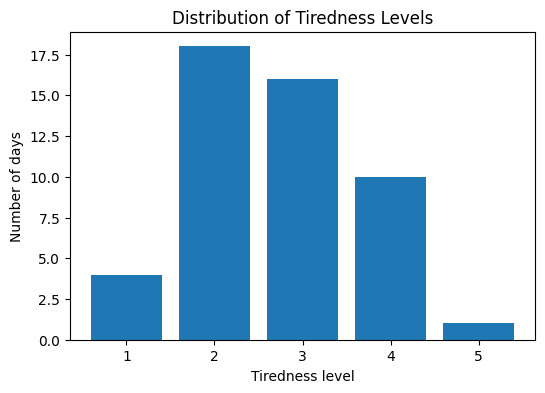

Mean tiredness: 2.71 | Median: 3.0


In [8]:
# Distribution of tiredness levels
tiredness_counts = df['tiredness'].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

plt.figure(figsize=(6, 4))
plt.bar(tiredness_counts.index, tiredness_counts.values)
plt.xlabel('Tiredness level')
plt.ylabel('Number of days')
plt.title('Distribution of Tiredness Levels')
plt.xticks([1, 2, 3, 4, 5])
plt.show()

print("Mean tiredness:", round(df['tiredness'].mean(), 2),
      "| Median:", df['tiredness'].median())

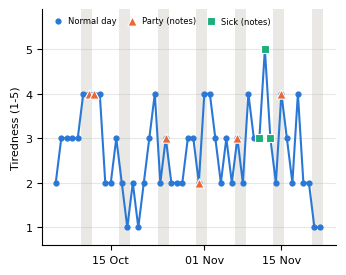

In [9]:
# Figure 1 (report): tiredness over time, with weekends shaded and exceptional days marked
plt.rcParams.update({'font.size': 8})
fig, ax = plt.subplots(figsize=(3.5, 2.8))

# Shade weekends
for d in df.loc[df['weekend'] == 1, 'date']:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12),
               color='#e9e8e4', linewidth=0)

ax.plot(df['date'], df['tiredness'], color='#2a78d6', linewidth=1.5, zorder=2)
ax.scatter(df['date'], df['tiredness'], color='#2a78d6', s=12, zorder=3, label='Normal day')

party = df[df['event_type'] == 'party']
sick = df[df['event_type'] == 'sick']
ax.scatter(party['date'], party['tiredness'], marker='^', s=45, color='#eb6834',
           edgecolor='white', linewidth=0.8, zorder=4, label='Party (notes)')
ax.scatter(sick['date'], sick['tiredness'], marker='s', s=40, color='#1baf7a',
           edgecolor='white', linewidth=0.8, zorder=4, label='Sick (notes)')

ax.set_ylabel('Tiredness (1-5)')
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylim(0.6, 5.9)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(bymonthday=[1, 15]))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d %b'))
ax.legend(loc='upper left', ncol=3, frameon=False, fontsize=6, handletextpad=0.2, columnspacing=0.8)
plt.tight_layout()
plt.savefig('figures/fig1_tiredness_timeline.png', dpi=300)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)

In [10]:
# Compare average tiredness by day type (with number of days)
for col, names in [('university_day', {0: 'No university', 1: 'University'}),
                   ('weekend', {0: 'Weekday', 1: 'Weekend'})]:
    summary = df.groupby(col)['tiredness'].agg(['count', 'mean']).round(2)
    summary.index = summary.index.map(names)
    display(summary)
    # Mann-Whitney U test (non-parametric, suitable for an ordinal variable)
    g0 = df.loc[df[col] == 0, 'tiredness']
    g1 = df.loc[df[col] == 1, 'tiredness']
    print(f"Mann-Whitney U p-value ({col}): {stats.mannwhitneyu(g0, g1).pvalue:.3f}\n")

,count,mean
university_day,,
No university,19,2.47
University,30,2.87


Mann-Whitney U p-value (university_day): 0.189



,count,mean
weekend,,
Weekday,35,2.8
Weekend,14,2.5


Mann-Whitney U p-value (weekend): 0.359



## 5. Correlation Analysis

Pearson measures linear relationships and Spearman monotonic relationships. Spearman is
the main measure because tiredness is an ordinal scale. We also report p-values: with
n = 49, only |rho| above about 0.28 is significant at the 5% level. Since we test 12 variables,
results with p close to 0.05 should be read with caution.

In [11]:
# Habit variables to correlate with tiredness
habit_vars = ['university_day', 'class_hours', 'study_hours', 'total_academic_hours',
              'sleep_hours', 'total_sleep_hours', 'nap_duration_min',
              'screen_time_hours', 'screen_before_bed_min',
              'gym_duration_min', 'steps', 'weekend']

def correlation_table(data, variables, target='tiredness'):
    """Pearson and Spearman correlations (with p-values) of each variable with the target."""
    rows = []
    for var in variables:
        r_p, p_p = stats.pearsonr(data[var], data[target])
        r_s, p_s = stats.spearmanr(data[var], data[target])
        rows.append({'variable': var, 'pearson': r_p, 'pearson_p': p_p,
                     'spearman': r_s, 'spearman_p': p_s})
    return pd.DataFrame(rows).set_index('variable')

correlation_results = correlation_table(df, habit_vars)
correlation_results = correlation_results.sort_values('spearman', key=abs, ascending=False)
display(correlation_results.round(3))

,pearson,pearson_p,spearman,spearman_p
variable,,,,
steps,0.288,0.045,0.323,0.024
screen_time_hours,0.247,0.087,0.311,0.030
sleep_hours,-0.247,0.087,-0.301,0.036
study_hours,-0.339,0.017,-0.269,0.062
total_sleep_hours,-0.167,0.251,-0.224,0.121
university_day,0.202,0.164,0.191,0.188
nap_duration_min,0.120,0.411,0.188,0.196
weekend,-0.143,0.327,-0.134,0.358
class_hours,0.103,0.483,0.117,0.424


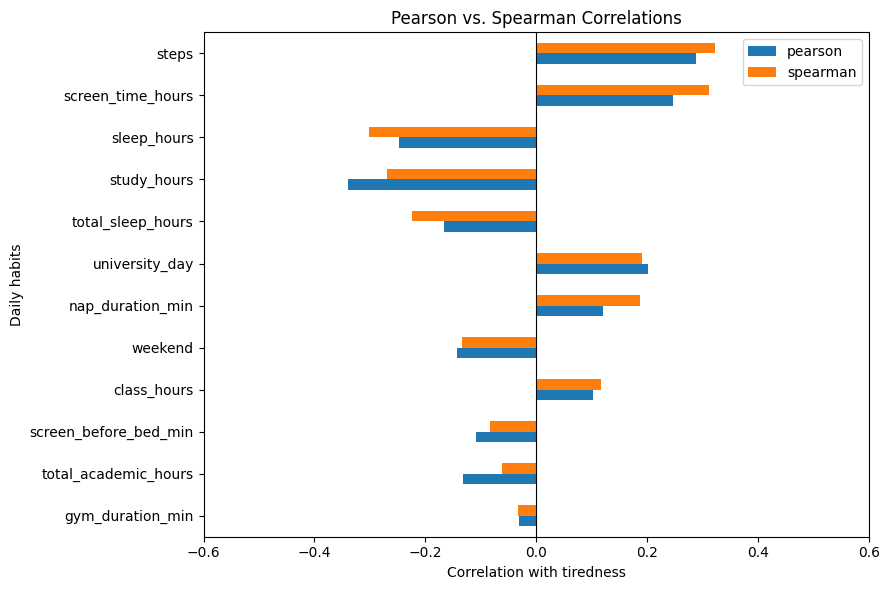

Spearman steps vs sleep_hours: -0.553 (p = 0.0000)


In [12]:
# Compare Pearson and Spearman correlations
plot_data = correlation_results[['pearson', 'spearman']].sort_values('spearman', key=abs)
plot_data.plot(kind='barh', figsize=(9, 6))
plt.xlabel('Correlation with tiredness')
plt.ylabel('Daily habits')
plt.title('Pearson vs. Spearman Correlations')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlim(-0.6, 0.6)
plt.tight_layout()
plt.show()

# Habits are also related to each other (e.g. early university days -> less sleep, more steps)
rho, p = stats.spearmanr(df['steps'], df['sleep_hours'])
print(f"Spearman steps vs sleep_hours: {rho:.3f} (p = {p:.4f})")

### 5.1 Sensitivity analysis: exceptional days

Party days and sick days are very different from my usual routine (e.g. very long sleep
when sick, short sleep and many steps when dancing). To check how much they influence the
correlations, we repeat the Spearman analysis **without** these 9 days. The main analysis
still uses all 49 days; this is only a robustness check.

In [13]:
normal_days = df[df['exceptional_day'] == 0]
print("Days without exceptional events:", len(normal_days))

sens_vars = ['sleep_hours', 'steps', 'screen_time_hours', 'study_hours',
             'university_day', 'total_sleep_hours', 'nap_duration_min', 'total_academic_hours',
             'gym_duration_min']

sensitivity = pd.DataFrame({
    'rho_all': [stats.spearmanr(df[v], df['tiredness'])[0] for v in sens_vars],
    'p_all': [stats.spearmanr(df[v], df['tiredness'])[1] for v in sens_vars],
    'rho_normal': [stats.spearmanr(normal_days[v], normal_days['tiredness'])[0] for v in sens_vars],
    'p_normal': [stats.spearmanr(normal_days[v], normal_days['tiredness'])[1] for v in sens_vars],
}, index=sens_vars)

display(sensitivity.round(3))

Days without exceptional events: 40


,rho_all,p_all,rho_normal,p_normal
sleep_hours,-0.301,0.036,-0.476,0.002
steps,0.323,0.024,0.417,0.007
screen_time_hours,0.311,0.030,0.278,0.083
study_hours,-0.269,0.062,-0.164,0.312
university_day,0.191,0.188,0.377,0.016
total_sleep_hours,-0.224,0.121,-0.349,0.027
nap_duration_min,0.188,0.196,0.142,0.382
total_academic_hours,-0.061,0.677,0.219,0.175
gym_duration_min,-0.033,0.823,0.115,0.481


## 6. Temporal Analysis

Does tiredness depend on sleep and workload over the previous days rather than only on
the current day? We compute 3-day rolling averages (the current value and the two previous
days) and compare their Spearman correlations with the daily values, using the **same 47 days**
for both. We also check other window sizes, to see if the result depends on choosing 3 days.

In [14]:
# 3-day rolling averages
df['sleep_3days'] = df['sleep_hours'].rolling(window=3).mean()
df['academic_3days'] = df['total_academic_hours'].rolling(window=3).mean()

display(df[['date', 'sleep_hours', 'sleep_3days',
            'total_academic_hours', 'academic_3days']].head(7))

# Same 47 observations for daily and 3-day values
temporal_df = df.dropna(subset=['sleep_3days', 'academic_3days'])

pairs = {'Sleep hours': ('sleep_hours', 'sleep_3days'),
         'Academic workload': ('total_academic_hours', 'academic_3days')}
rows = []
for name, (daily, avg3) in pairs.items():
    r_d, p_d = stats.spearmanr(temporal_df[daily], temporal_df['tiredness'])
    r_3, p_3 = stats.spearmanr(temporal_df[avg3], temporal_df['tiredness'])
    rows.append({'variable': name, 'daily': r_d, 'daily_p': p_d,
                 '3-day average': r_3, '3-day_p': p_3})
temporal_results = pd.DataFrame(rows).set_index('variable')
print("n =", len(temporal_df))
display(temporal_results.round(3))

# Same comparison without exceptional days
temporal_normal = temporal_df[temporal_df['exceptional_day'] == 0]
print("Without exceptional days (n = %d):" % len(temporal_normal))
for col in ['sleep_hours', 'sleep_3days']:
    r, p = stats.spearmanr(temporal_normal[col], temporal_normal['tiredness'])
    print(f"  {col}: rho = {r:.3f} (p = {p:.4f})")

,date,sleep_hours,sleep_3days,total_academic_hours,academic_3days
0,2026-10-05,8.75,NaN,6,NaN
1,2026-10-06,6.75,NaN,7,NaN
2,2026-10-07,7.00,7.500000,9,7.333333
3,2026-10-08,7.00,6.916667,6,7.333333
4,2026-10-09,7.00,7.000000,9,8.000000
5,2026-10-10,7.50,7.166667,4,6.333333
6,2026-10-11,5.50,6.666667,0,4.333333


n = 47


,daily,daily_p,3-day average,3-day_p
variable,,,,
Sleep hours,-0.285,0.052,-0.431,0.003
Academic workload,-0.069,0.647,-0.200,0.179


Without exceptional days (n = 38):
  sleep_hours: rho = -0.463 (p = 0.0034)
  sleep_3days: rho = -0.614 (p = 0.0000)


sample,All days,Without exceptional days
window_days,,
1,-0.301,-0.476
2,-0.323,-0.460
3,-0.431,-0.614
4,-0.278,-0.514
5,-0.180,-0.436
6,-0.142,-0.319
7,-0.087,-0.226


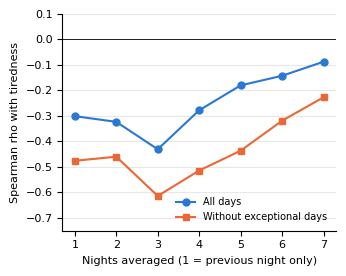

In [15]:
# Robustness: Spearman correlation of tiredness with sleep averaged over 1-7 days
windows = range(1, 8)
window_rows = []
for w in windows:
    for label in ['All days', 'Without exceptional days']:
        sleep_avg = df['sleep_hours'].rolling(window=w).mean()
        mask = sleep_avg.notna()
        if label == 'Without exceptional days':
            mask = mask & (df['exceptional_day'] == 0)
        r, p = stats.spearmanr(sleep_avg[mask], df.loc[mask, 'tiredness'])
        window_rows.append({'window_days': w, 'sample': label, 'rho': r, 'p': p, 'n': mask.sum()})
window_results = pd.DataFrame(window_rows)
display(window_results.pivot(index='window_days', columns='sample', values='rho').round(3))

# Figure 2 (report)
plt.rcParams.update({'font.size': 8})
fig, ax = plt.subplots(figsize=(3.5, 2.8))
styles = {'All days': ('#2a78d6', 'o'), 'Without exceptional days': ('#eb6834', 's')}
for label, (color, marker) in styles.items():
    sub = window_results[window_results['sample'] == label]
    ax.plot(sub['window_days'], sub['rho'], color=color, marker=marker,
            markersize=5, linewidth=1.5, label=label)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('Nights averaged (1 = previous night only)')
ax.set_ylabel('Spearman rho with tiredness')
ax.set_xticks(list(windows))
ax.set_ylim(-0.75, 0.1)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig('figures/fig2_sleep_window.png', dpi=300)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)

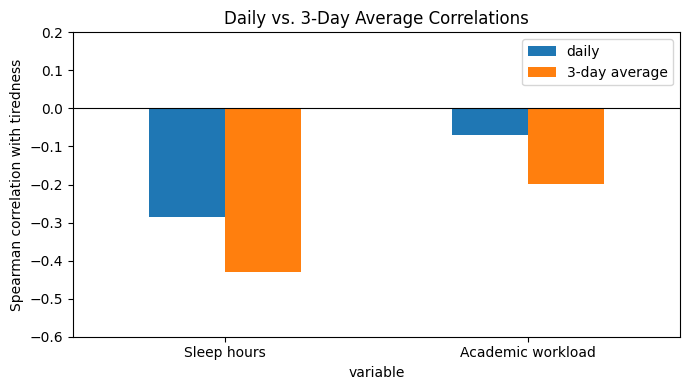

In [16]:
# Daily vs. 3-day average correlations (bar chart)
temporal_results[['daily', '3-day average']].plot(kind='bar', figsize=(7, 4))
plt.ylabel('Spearman correlation with tiredness')
plt.title('Daily vs. 3-Day Average Correlations')
plt.xticks(rotation=0)
plt.axhline(0, color='black', linewidth=0.8)
plt.ylim(-0.6, 0.2)
plt.tight_layout()
plt.show()

## 7. Clustering

K-means is used to find groups of days with similar habits. Tiredness is **not** used to
build the clusters; it is compared between clusters afterwards. The variables are
standardized first because they have very different scales (hours, minutes, steps).

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Daily habits used for clustering
features = ['sleep_hours', 'nap_duration_min', 'total_academic_hours',
            'screen_time_hours', 'screen_before_bed_min', 'gym_duration_min', 'steps']

X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

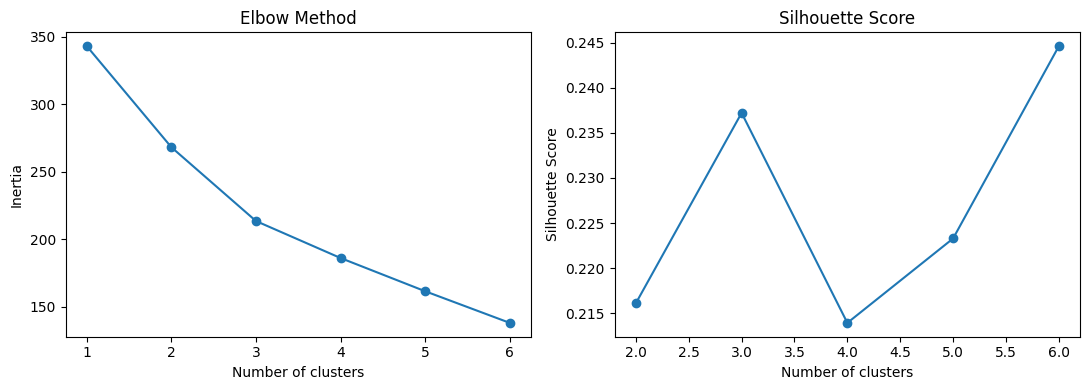

k=2: Silhouette Score = 0.216
k=3: Silhouette Score = 0.237
k=4: Silhouette Score = 0.214
k=5: Silhouette Score = 0.223
k=6: Silhouette Score = 0.245


In [18]:
# Evaluate different numbers of clusters
inertias = []
silhouette_scores = []

for k in range(1, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, 7), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Inertia')
axes[1].plot(range(2, 7), silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

for k, score in zip(range(2, 7), silhouette_scores):
    print(f"k={k}: Silhouette Score = {score:.3f}")

In [19]:
# Apply K-means with 3 clusters (interpretable and not too fragmented for 49 days)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("Days per cluster:")
print(df['cluster'].value_counts().sort_index())

# Average habits for each cluster (original units)
cluster_profiles = df.groupby('cluster')[features].mean()
display(cluster_profiles.T.round(2))

# Tiredness by cluster
cluster_tiredness = df.groupby('cluster')['tiredness'].agg(['count', 'mean', 'median', 'std']).round(2)
display(cluster_tiredness)

Days per cluster:
cluster
0    10
1    12
2    27
Name: count, dtype: int64


cluster,0,1,2
sleep_hours,6.28,8.69,7.27
nap_duration_min,105.00,5.00,14.26
total_academic_hours,2.60,4.17,7.81
screen_time_hours,3.90,3.48,3.85
screen_before_bed_min,1.00,3.33,30.19
gym_duration_min,9.00,15.00,50.00
steps,7692.30,3910.17,8061.30


,count,mean,median,std
cluster,,,,
0,10,3.10,3.5,1.10
1,12,2.42,2.0,1.16
2,27,2.70,3.0,0.78


In [20]:
# What do the clusters correspond to? Compare with the calendar and the exceptional days
display(pd.crosstab(df['cluster'], df['weekend'].map({0: 'weekday', 1: 'weekend'})))
display(pd.crosstab(df['cluster'], df['event_type']))
display(df.groupby('cluster')['university_day'].mean().round(2).rename('share_university_days'))

# Is tiredness different between clusters? Kruskal-Wallis test (non-parametric)
groups = [g['tiredness'] for _, g in df.groupby('cluster')]
kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")

# Stability: how similar are the clusters with other random initialisations?
aris = []
for seed in range(10):
    labels_seed = KMeans(n_clusters=3, random_state=seed, n_init=10).fit_predict(X_scaled)
    aris.append(adjusted_rand_score(df['cluster'], labels_seed))
print("Adjusted Rand Index vs. seed 42 (1 = identical):", np.round(aris, 2))

weekend,weekday,weekend
cluster,,
0,1,9
1,7,5
2,27,0


event_type,normal,party,sick
cluster,,,
0,5,5,0
1,9,1,2
2,26,0,1


,share_university_days
cluster,
0,0.10
1,0.33
2,0.93


Kruskal-Wallis: H = 3.47, p = 0.177
Adjusted Rand Index vs. seed 42 (1 = identical): [0.87 0.93 1.   0.75 1.   1.   1.   1.   1.   1.  ]


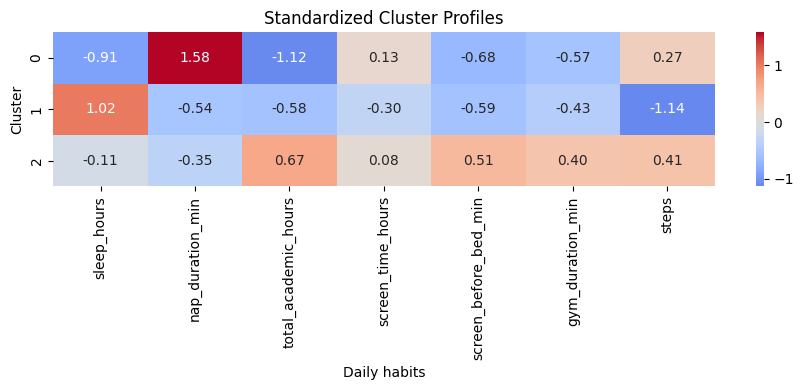

In [21]:
# Visualize standardized cluster profiles
centers = pd.DataFrame(kmeans.cluster_centers_, columns=features)

plt.figure(figsize=(9, 4))
sns.heatmap(centers, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Standardized Cluster Profiles')
plt.xlabel('Daily habits')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

## 8. Export Results

The processed dataset and the result tables are exported to `results/` for reproducibility.

In [22]:
df.to_csv('results/tiredness_processed.csv', index=False)
correlation_results.to_csv('results/correlation_results.csv')
sensitivity.to_csv('results/sensitivity_results.csv')
temporal_results.to_csv('results/temporal_results.csv')
window_results.to_csv('results/sleep_window_results.csv', index=False)
cluster_profiles.to_csv('results/cluster_profiles.csv')
cluster_tiredness.to_csv('results/cluster_tiredness.csv')
print("Results exported to results/ and figures to figures/")

Results exported to results/ and figures to figures/
